In [1]:
import pandas as pd
import matplotlib.pyplot as plt

This is a script/notebook to semi-manually post-process captured data.

We synchronize using the LED in the video and optionally cut out some data

Plot the raw data to get an overview

<Axes: >

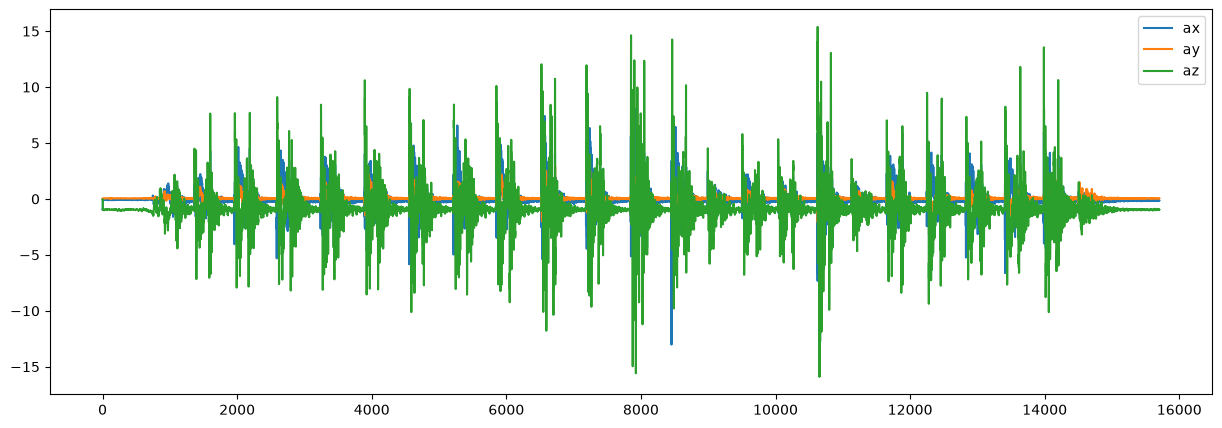

In [31]:
file = "take7"
folder = "2026-09-23"
video_name = "GX018881"
accel = pd.read_csv(f"../../data/{folder}/data/{file}.csv")[["ax", "ay", "az"]]
accel.plot(figsize=(15, 5))

Load the event extracted from the video. Shift everything to the LED signal.

In [36]:
events = pd.read_csv(f"../../data/{folder}/video_truth/{video_name}_{file}_events.csv", comment="#", delimiter=";")[["Event", "Frame"]].rename(columns={"Frame": "Video_Frame"})
# Use "Led on" event as zero timestamp
# sync_frame = events[events["Event"] == "LED on"]["Video_Frame"].values[0]
sync_frame = 700
events["Video_Frame"] -= sync_frame
# convert video frame to sensor frames
events["Sensor_Frame"] = events["Video_Frame"] / 240 * 416
events

,Event,Video_Frame,Sensor_Frame
0,Landing,481,833.733333
1,Takeoff,608,1053.866667
2,Landing,778,1348.533333
3,Takeoff,890,1542.666667
4,Landing,1123,1946.533333
5,Takeoff,1227,2126.800000
6,Landing,1485,2574.000000
7,Takeoff,1587,2750.800000
8,Landing,1859,3222.266667
9,Takeoff,1959,3395.600000


Decide for a `cut_region` and overlay the event on the raw signal to see if this makes sense.

(1100.0, 14300.0)

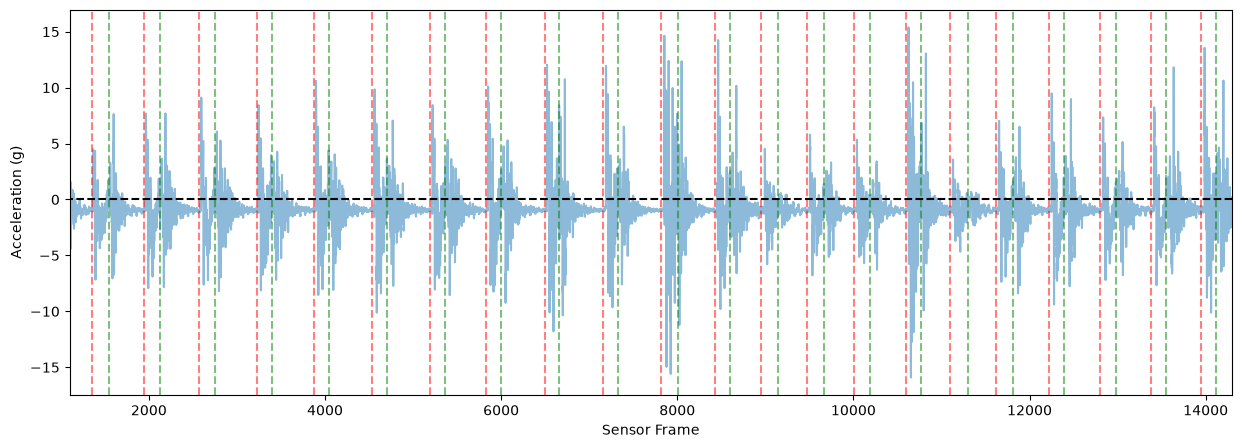

In [40]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(accel["az"], label="Raw Acceleration", alpha=0.5)
for _, row in events.iterrows():
    if row["Event"] == "Takeoff":
        ax.axvline(row["Sensor_Frame"], color='g', linestyle='--', label='Takeoff', alpha=0.5)
    elif row["Event"] == "Landing":
        ax.axvline(row["Sensor_Frame"], color='r', linestyle='--', label='Landing', alpha=0.5)
ax.set_xlabel("Sensor Frame")
ax.set_ylabel("Acceleration (g)")
ax.hlines(0, 0, len(accel), colors='k', linestyles='dashed')


cut_region = [1100, 14300]

ax.set_xlim(*cut_region)

Write out the cutted data

In [ ]:
az_cut = pd.DataFrame(accel["az"][slice(*cut_region)])
az_cut.index -= cut_region[0]
az_cut.to_csv(f"../../data/cleaned/{folder}_{file}.csv", index_label="frame")

In [ ]:
events_cut = events[(events["Sensor_Frame"] >= cut_region[0]) & (events["Sensor_Frame"] <= cut_region[1])].set_index("Sensor_Frame")
events_cut.index -= cut_region[0]
events_cut.to_csv(f"../../data/cleaned/{folder}_{file}_events.csv", columns=["Event"])